In [ ]:
import marimo as mo
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy

rng = np.random.default_rng(seed=69)

## Задание 1.

### Задание 1. Синтетический тест
![alt](public/image_1.png)

In [ ]:
def normalize(arr):
    return arr / np.linalg.norm(arr, axis=1, keepdims=True)

def cos(x, y):
    return np.sum(x * y, axis=1)

def vectorize(d, M=20_000):
    X = rng.standard_normal((M, d))
    Y = rng.standard_normal((M, d))

    X_norm = normalize(X)
    Y_norm = normalize(Y)

    S = cos(X_norm, Y_norm)
    return S

![](public/image_3.png)

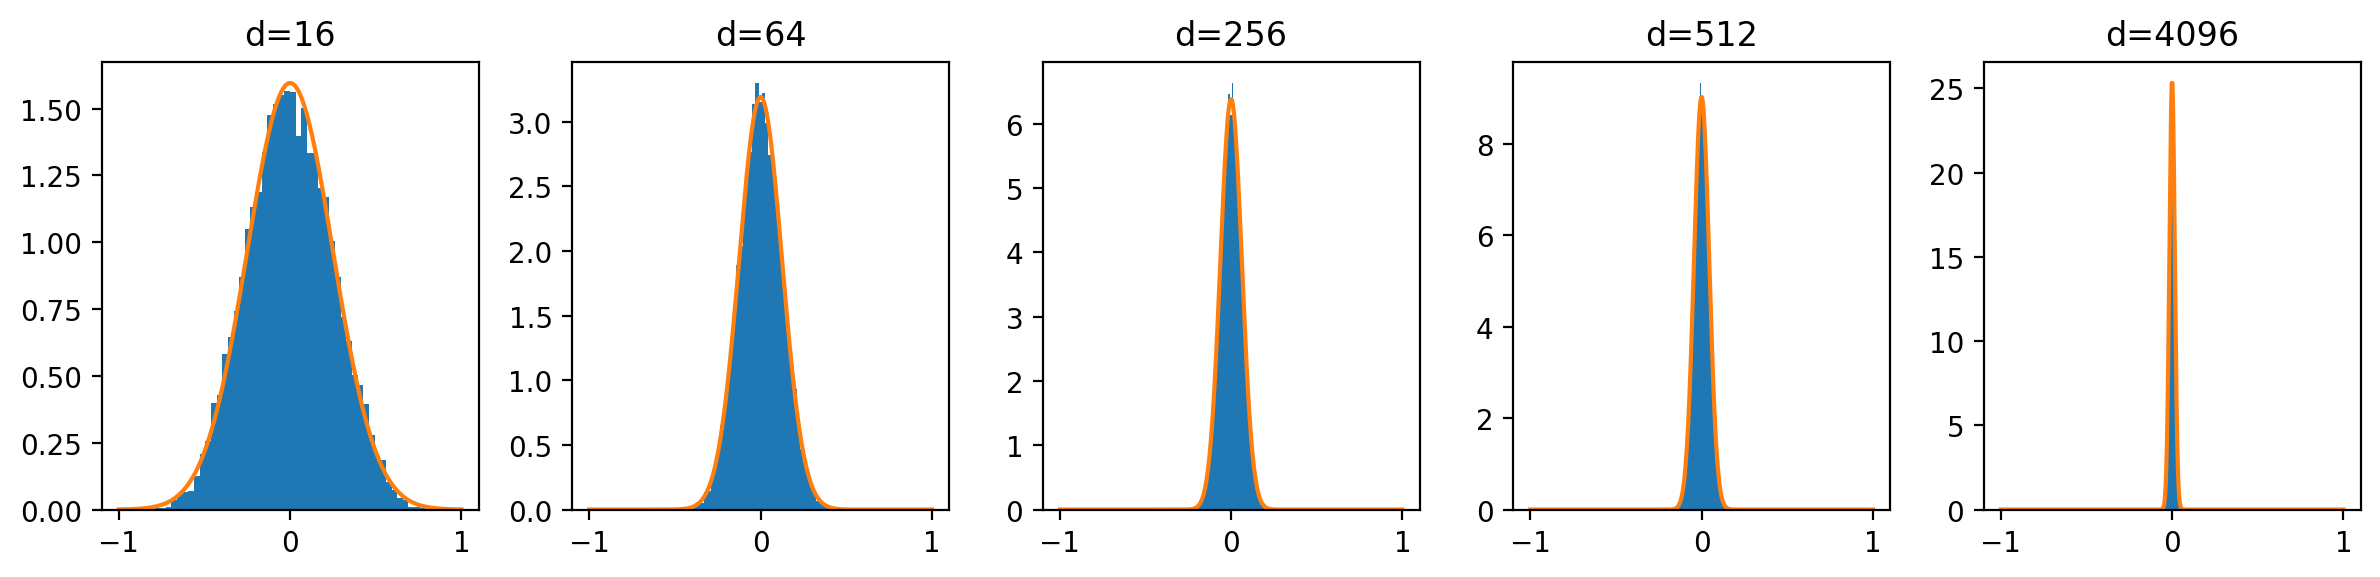

<span class="markdown prose dark:prose-invert contents"><table>
<thead>
<tr>
<th style="text-align: right;">d</th>
<th style="text-align: right;">$\sigma^2_{\text{теор}}$</th>
<th style="text-align: right;">$\hat{\sigma}^2$</th>
<th style="text-align: right;">$\hat{\mu}$</th>
<th style="text-align: right;">kurtosis</th>
</tr>
</thead>
<tbody>
<tr>
<td style="text-align: right;">16</td>
<td style="text-align: right;">0.0625</td>
<td style="text-align: right;">0.0612</td>
<td style="text-align: right;">-0.0006</td>
<td style="text-align: right;">-0.306</td>
</tr>
<tr>
<td style="text-align: right;">64</td>
<td style="text-align: right;">0.0156</td>
<td style="text-align: right;">0.0154</td>
<td style="text-align: right;">0.0002</td>
<td style="text-align: right;">-0.091</td>
</tr>
<tr>
<td style="text-align: right;">256</td>
<td style="text-align: right;">0.0039</td>
<td style="text-align: right;">0.0039</td>
<td style="text-align: right;">-0.0001</td>
<td style="text-align: right;">-0.0552</td>
</tr>
<tr>
<td style="text-align: right;">512</td>
<td style="text-align: right;">0.002</td>
<td style="text-align: right;">0.0019</td>
<td style="text-align: right;">0.0003</td>
<td style="text-align: right;">-0.0169</td>
</tr>
<tr>
<td style="text-align: right;">4096</td>
<td style="text-align: right;">0.0002</td>
<td style="text-align: right;">0.0002</td>
<td style="text-align: right;">-0</td>
<td style="text-align: right;">-0.0328</td>
</tr>
</tbody>
</table></span>

In [ ]:
D = [16, 64, 256, 512, 4096]
S = {}
_fig, _ax = plt.subplots(1, len(D), figsize=(12, 3))
for axes, d in zip(_ax, D):
    s_d = vectorize(d)
    S[d] = s_d

    _x = np.linspace(-1, 1, 500)
    _density = scipy.stats.norm.pdf(_x, scale=1/np.sqrt(d))

    axes.hist(s_d, bins=50, density=True)
    axes.plot(_x, _density)
    axes.set_title(f'd={d}')

_fig.tight_layout()
plt.show()

rows = []
for d, s in S.items():
    rows.append({
        'd': d,
        r'$\sigma^2_{\text{теор}}$': f'{1 / d:.4f}',
        r'$\hat{\sigma}^2$': f'{s.var():.4f}',
        r'$\hat{\mu}$': f'{s.mean():.4f}',
        r'kurtosis': f'{scipy.stats.kurtosis(s):.4f}'
    })

df = pd.DataFrame(rows).set_index('d')
mo.md(df.to_markdown())

![alt](public/image.png)

In [ ]:
def check_cone(weights, xlim=[-0.25, 0.25]):
    W = normalize(weights)
    print(f'W shape = {W.shape}')
    i, j = rng.integers(0, len(W), size=10_000), rng.integers(0, len(W), size=10_000)

    Sw = cos(W[i], W[j])[i != j]
    print(f'Sw shape = {Sw.shape}')

    fig, ax = plt.subplots()

    x = np.linspace(-1, 1, 512)
    density = scipy.stats.norm.pdf(x, scale=1 / np.sqrt(512))

    ax.hist(Sw, bins=50, density=True)
    ax.plot(x, density)

    ax.set_xlim(xlim)
    plt.show()

    return mo.md(rf'Sw mean = {Sw.mean():.4f}, Sw var = {Sw.var():.4f}, $\sigma^2$ = {1 / 512:.5f}')


W shape = (50277, 512)
Sw shape = (9999,)


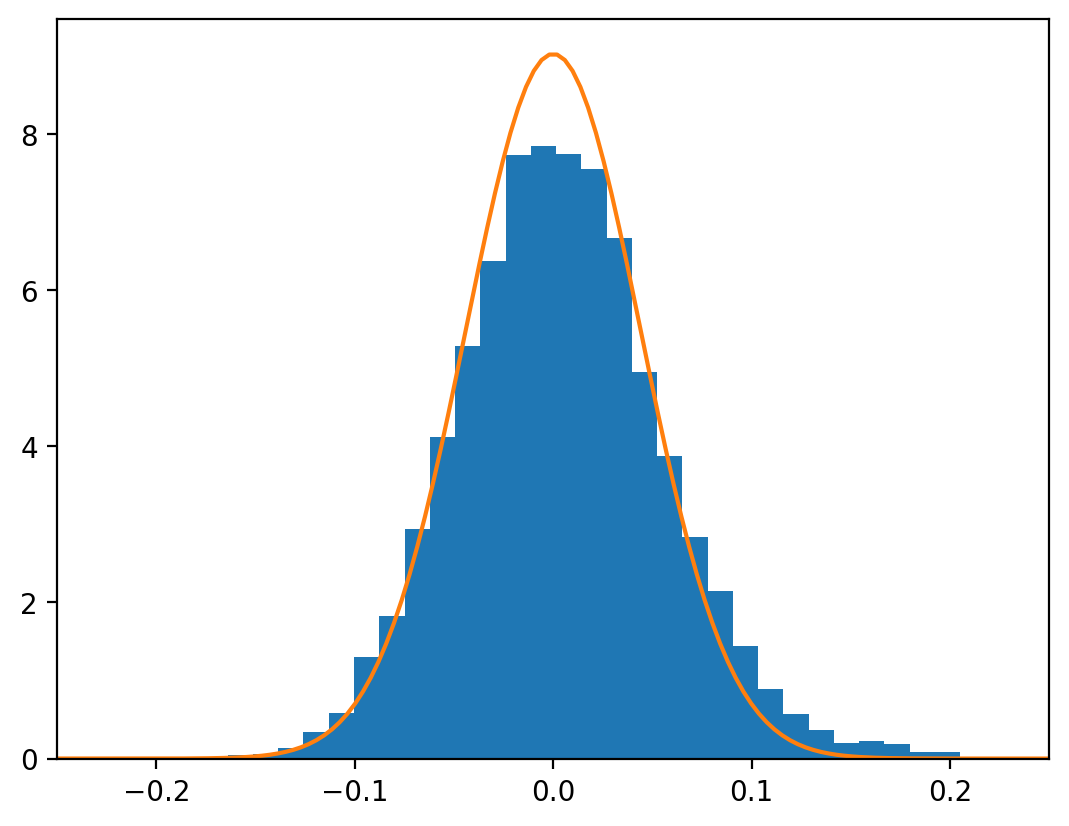

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Sw mean = 0.0045, Sw var = 0.0028, $\sigma^2$ = 0.00195</span></span>

In [ ]:
from transformers import AutoModelForCausalLM

name = "EleutherAI/pythia-70m"

model = AutoModelForCausalLM.from_pretrained(name)

W_in = model.gpt_neox.embed_in.weight.detach().numpy()[:50277]

check_cone(W_in)

W shape = (50277, 512)
Sw shape = (9999,)


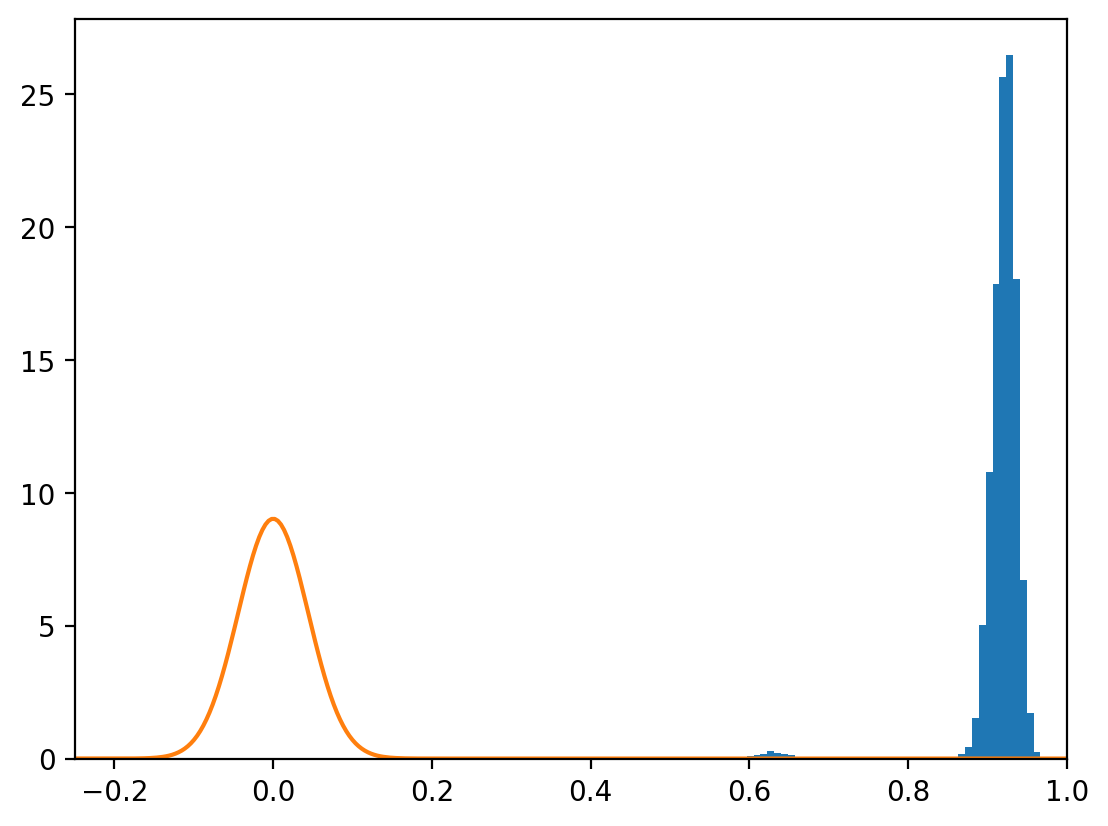

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Sw mean = 0.9180, Sw var = 0.0012, $\sigma^2$ = 0.00195</span></span>

In [ ]:
W_out = model.embed_out.weight.detach().numpy()[:50277]
check_cone(W_out, xlim=[-0.25, 1])

W shape = (50277, 512)
Sw shape = (10000,)


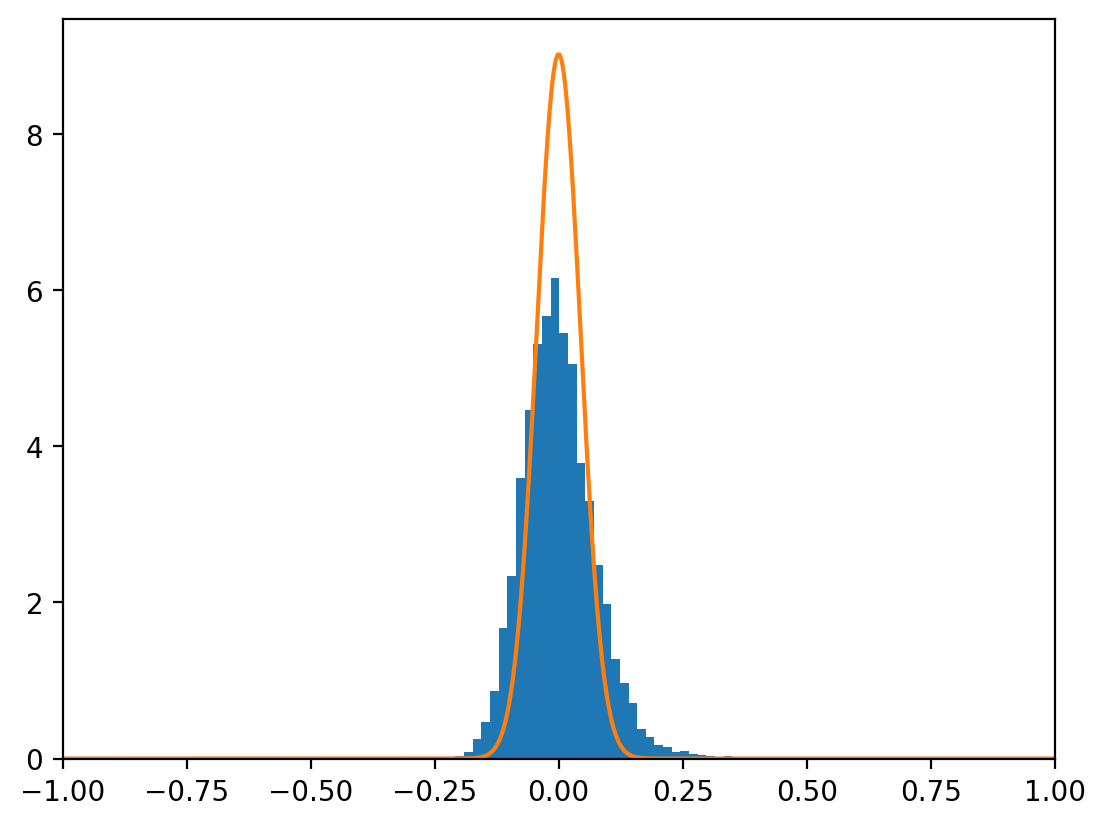

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Sw mean = 0.0005, Sw var = 0.0054, $\sigma^2$ = 0.00195</span></span>

In [ ]:
W_centred = W_out - W_out.mean(axis=0)
check_cone(W_centred, xlim=[-1,1])

W shape = (50277, 512)
Sw shape = (10000,)


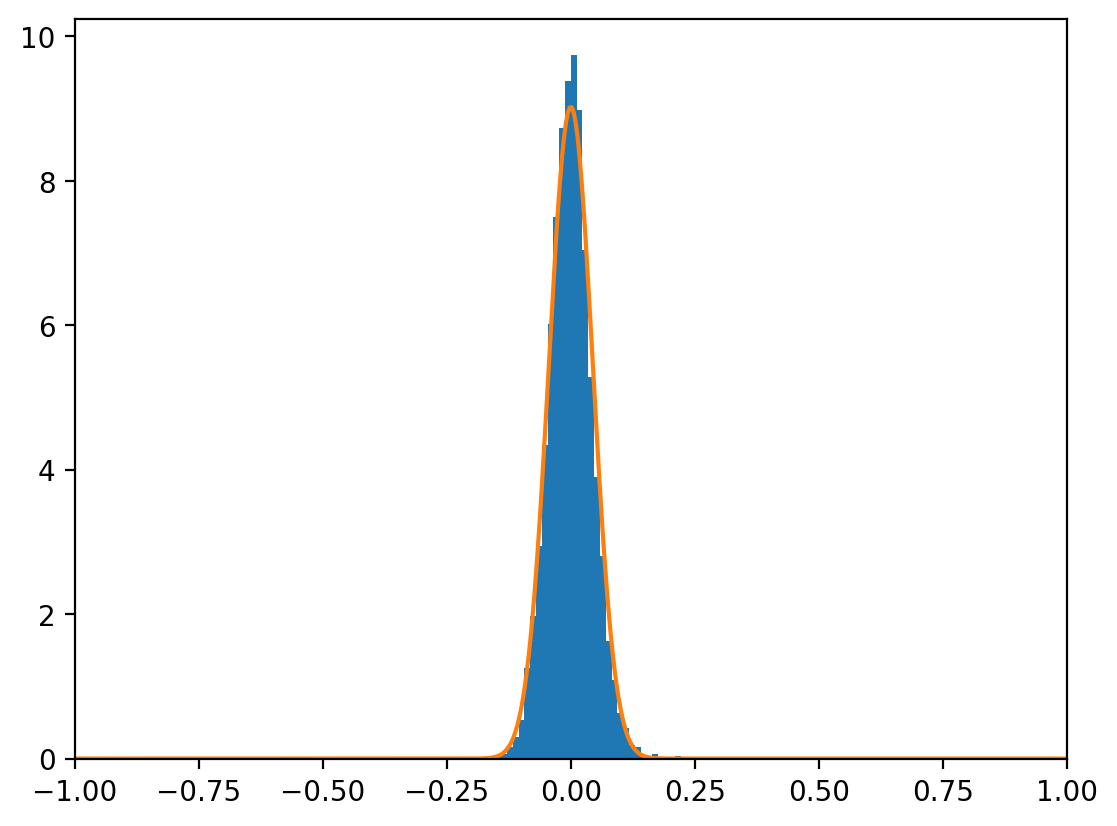

<span class="markdown prose dark:prose-invert contents"><span class="paragraph">Sw mean = -0.0002, Sw var = 0.0019, $\sigma^2$ = 0.00195</span></span>

In [ ]:
W_svd, _S, Vt = np.linalg.svd(W_centred, full_matrices=False)

check_cone(W_svd, xlim=[-1, 1])